In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Load datasets
train_df = pd.read_csv("/Users/kushagra/Downloads/industrial-machine-condition-classification-mtech/student_dataset.csv")
test_df = pd.read_csv("/Users/kushagra/Downloads/industrial-machine-condition-classification-mtech/test.csv")
sample_sub = pd.read_csv("/Users/kushagra/Downloads/industrial-machine-condition-classification-mtech/sample_submission.csv")

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape:  {test_df.shape}")
print(f"Sample Sub:  {sample_sub.shape}")
train_df.head()

Train Shape: (16000, 13)
Test Shape:  (4000, 12)
Sample Sub:  (4000, 2)


,unit_id,unit_type,ambient_temp,process_temp,coolant_flow,shaft_speed,drive_torque,power_load,component_wear,thermal_stress,mechanical_load,vibration_index,condition
0,UNT-184174,M,21.5,56.4,17.85,1454.0,58.2,9.099,30.0,29.31,57.19,1.768,0
1,UNT-236234,H,29.9,65.0,30.88,1720.0,54.6,10.101,13.0,23.93,36.94,1.081,0
2,UNT-247460,M,26.4,47.8,19.75,1552.0,38.4,6.328,89.0,13.52,38.22,1.031,0
3,UNT-176316,M,28.8,60.9,19.10,1513.0,49.1,7.768,59.0,24.62,46.17,1.011,0
4,UNT-105110,S,29.4,64.0,11.77,1536.0,52.6,8.405,36.0,27.83,94.72,1.851,1


/var/folders/4r/77g19d0s1rs9c63j_jp9d09h0000gn/T/ipykernel_9719/4179900429.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette="viridis")


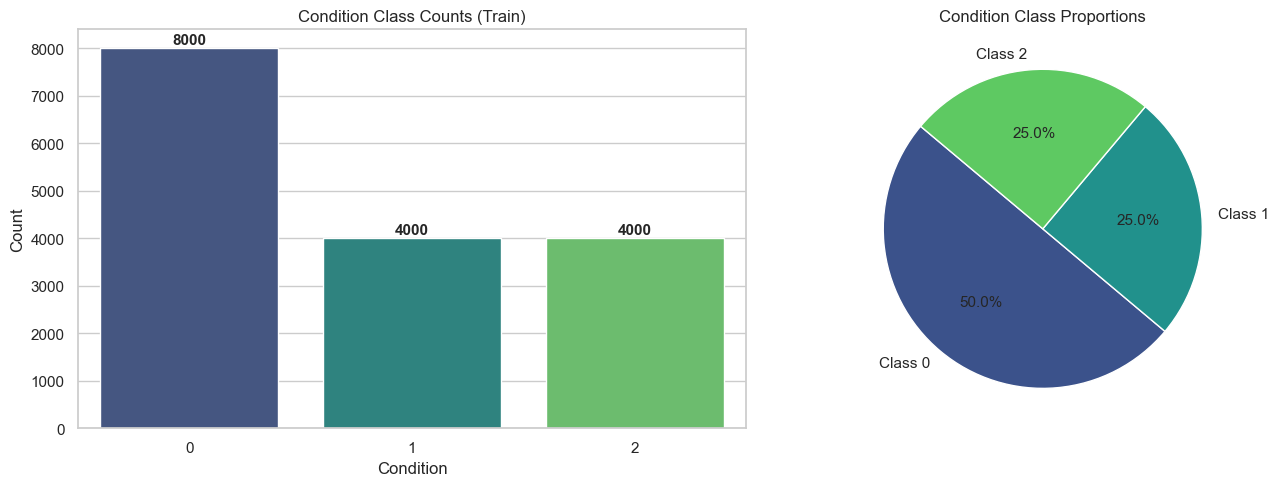

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Target count and percentage
counts = train_df["condition"].value_counts().sort_index()
proportions = train_df["condition"].value_counts(normalize=True).sort_index()

sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette="viridis")
ax[0].set_title("Condition Class Counts (Train)")
ax[0].set_xlabel("Condition")
ax[0].set_ylabel("Count")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 100, str(v), ha="center", fontweight="bold")

ax[1].pie(
    proportions,
    labels=[f"Class {i}" for i in proportions.index],
    autopct="%1.1f%%",
    colors=sns.color_palette("viridis", len(proportions)),
    startangle=140,
)
ax[1].set_title("Condition Class Proportions")

plt.tight_layout()
plt.show()

In [3]:
# Check missing values comparison between Train and Test
missing_train = train_df.isnull().sum()
missing_test = test_df.isnull().sum()

missing_table = pd.DataFrame(
    {
        "Train Missing": missing_train,
        "Train Missing (%)": (missing_train / len(train_df)) * 100,
        "Test Missing": missing_test,
        "Test Missing (%)": (missing_test / len(test_df)) * 100,
    }
).dropna(subset=["Train Missing"])

print("--- Missing Values Summary ---")
display(
    missing_table[
        (missing_table["Train Missing"] > 0)
        | (missing_table["Test Missing"] > 0)
    ]
)

# Statistical description of continuous variables
train_df.describe().T.drop("condition", errors="ignore")

--- Missing Values Summary ---


,Train Missing,Train Missing (%),Test Missing,Test Missing (%)
ambient_temp,47,0.29375,10.0,0.250
component_wear,56,0.35000,15.0,0.375
coolant_flow,61,0.38125,12.0,0.300
drive_torque,36,0.22500,12.0,0.300
mechanical_load,45,0.28125,3.0,0.075
power_load,25,0.15625,8.0,0.200
process_temp,45,0.28125,13.0,0.325
shaft_speed,32,0.20000,8.0,0.200
thermal_stress,50,0.31250,16.0,0.400
unit_type,22,0.13750,11.0,0.275


,count,mean,std,min,25%,50%,75%,max
ambient_temp,15953.0,25.981113,4.926352,12.000,22.300,24.900,29.900,41.200
process_temp,15955.0,60.985653,11.098875,33.600,52.900,59.800,67.600,116.900
coolant_flow,15939.0,17.876902,6.112769,7.820,12.380,17.620,22.130,37.140
shaft_speed,15968.0,1519.399737,262.652572,824.000,1324.000,1496.000,1693.000,2574.000
drive_torque,15964.0,55.029216,11.448610,25.100,46.800,54.100,62.400,95.000
power_load,15975.0,8.961852,3.137047,2.749,6.619,8.444,10.817,23.956
component_wear,15944.0,108.325702,67.347098,3.000,58.000,94.000,144.000,340.000
thermal_stress,15950.0,27.674356,10.805493,7.360,19.660,25.745,33.760,84.670
mechanical_load,15955.0,72.483153,24.233399,25.490,53.480,68.090,88.885,180.420
vibration_index,15926.0,1.690895,0.493647,0.612,1.337,1.617,1.965,5.534


/var/folders/4r/77g19d0s1rs9c63j_jp9d09h0000gn/T/ipykernel_9719/3896269100.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


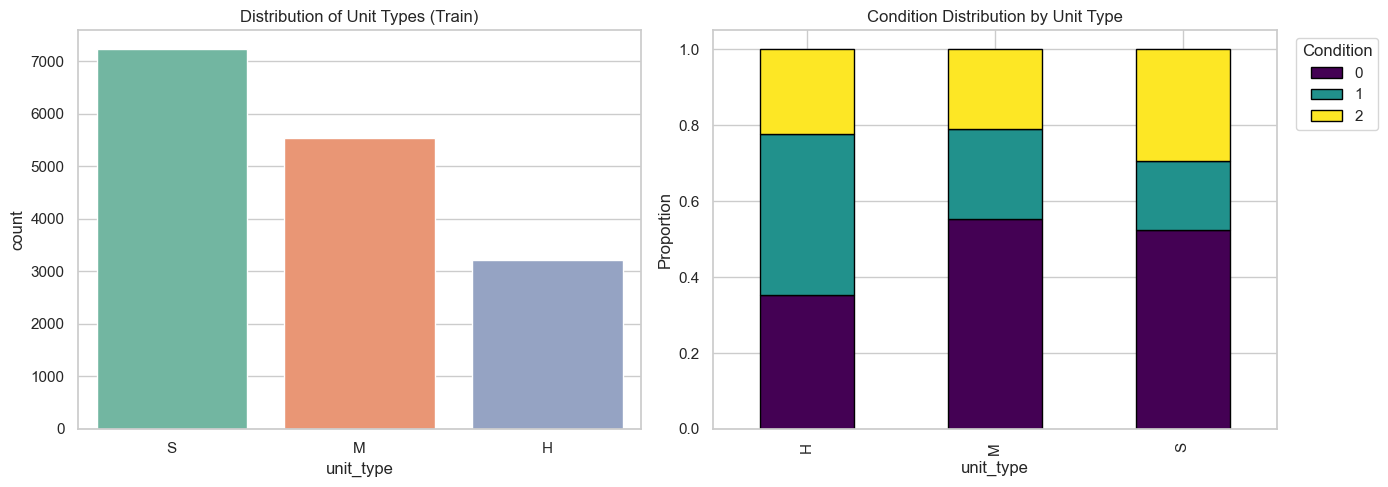

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Unit type counts
sns.countplot(
    data=train_df, x="unit_type", order=["S", "M", "H"], ax=ax[0], palette="Set2"
)
ax[0].set_title("Distribution of Unit Types (Train)")

# Unit type vs Condition proportion
unit_cond_pct = pd.crosstab(
    train_df["unit_type"], train_df["condition"], normalize="index"
)
unit_cond_pct.plot(
    kind="bar", stacked=True, ax=ax[1], colormap="viridis", edgecolor="black"
)
ax[1].set_title("Condition Distribution by Unit Type")
ax[1].set_ylabel("Proportion")
ax[1].legend(title="Condition", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

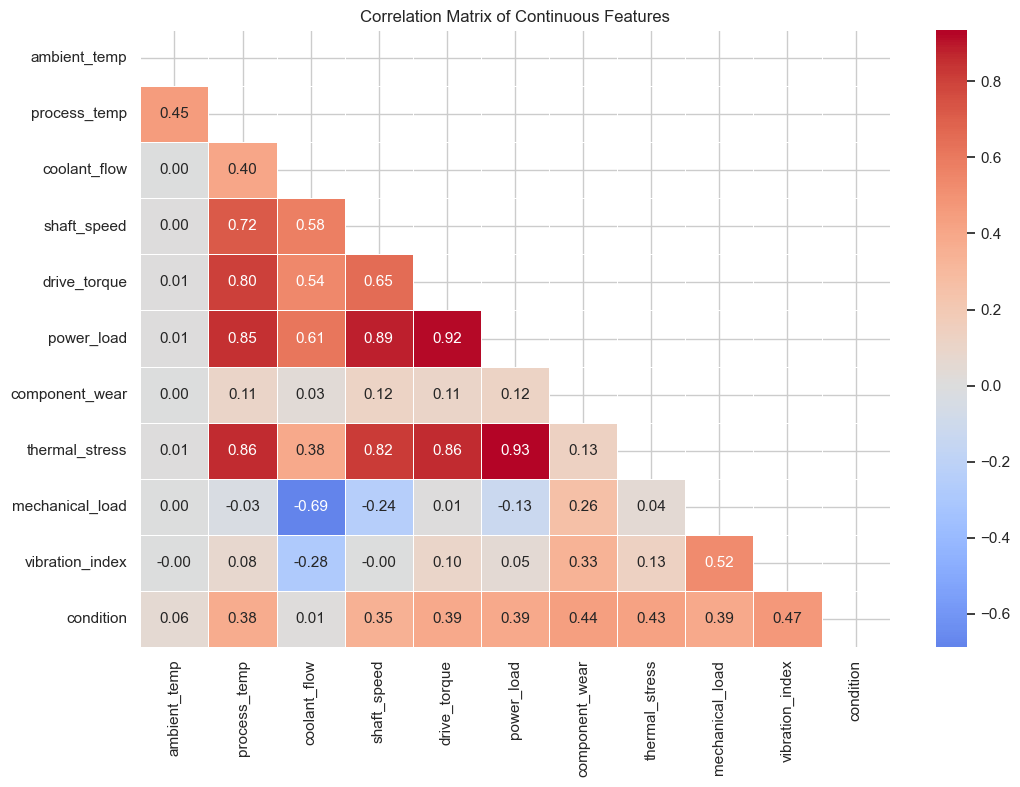

In [5]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(11, 8))
corr_matrix = train_df[numeric_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
)
plt.title("Correlation Matrix of Continuous Features")
plt.tight_layout()
plt.show()

/var/folders/4r/77g19d0s1rs9c63j_jp9d09h0000gn/T/ipykernel_9719/2178990731.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/4r/77g19d0s1rs9c63j_jp9d09h0000gn/T/ipykernel_9719/2178990731.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/4r/77g19d0s1rs9c63j_jp9d09h0000gn/T/ipykernel_9719/2178990731.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/4r/77g19d0s1rs9c63j_jp9d09h0000gn/T/ipykernel_9719/2178990731.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

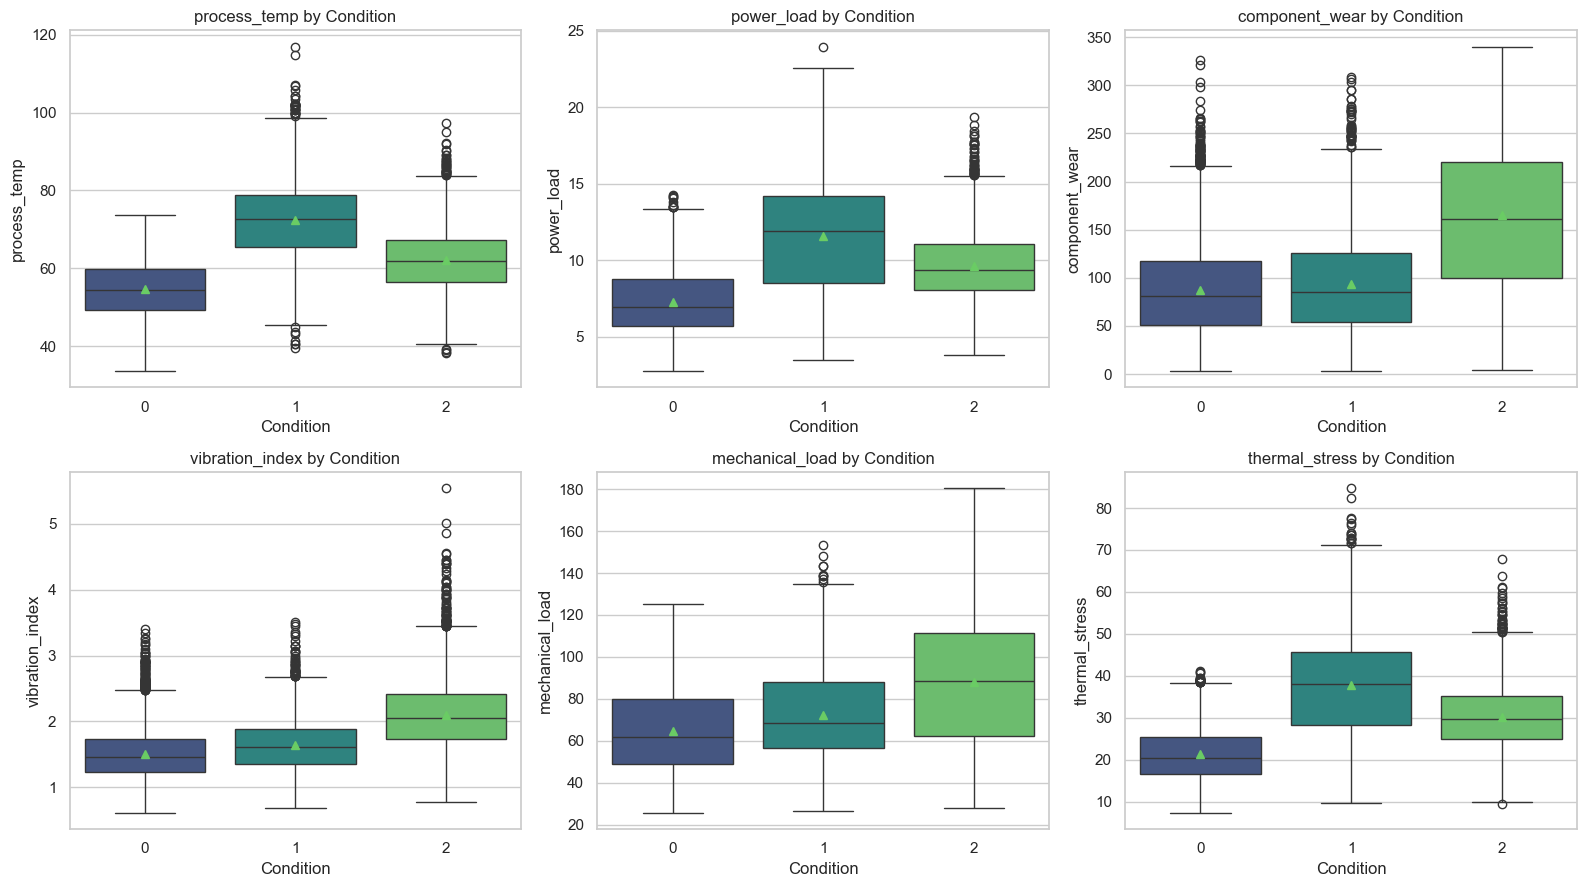

In [6]:
features_to_plot = [
    "process_temp",
    "power_load",
    "component_wear",
    "vibration_index",
    "mechanical_load",
    "thermal_stress",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, col in enumerate(features_to_plot):
    sns.boxplot(
        data=train_df,
        x="condition",
        y=col,
        ax=axes[idx],
        palette="viridis",
        showmeans=True,
    )
    axes[idx].set_title(f"{col} by Condition")
    axes[idx].set_xlabel("Condition")

plt.tight_layout()
plt.show()

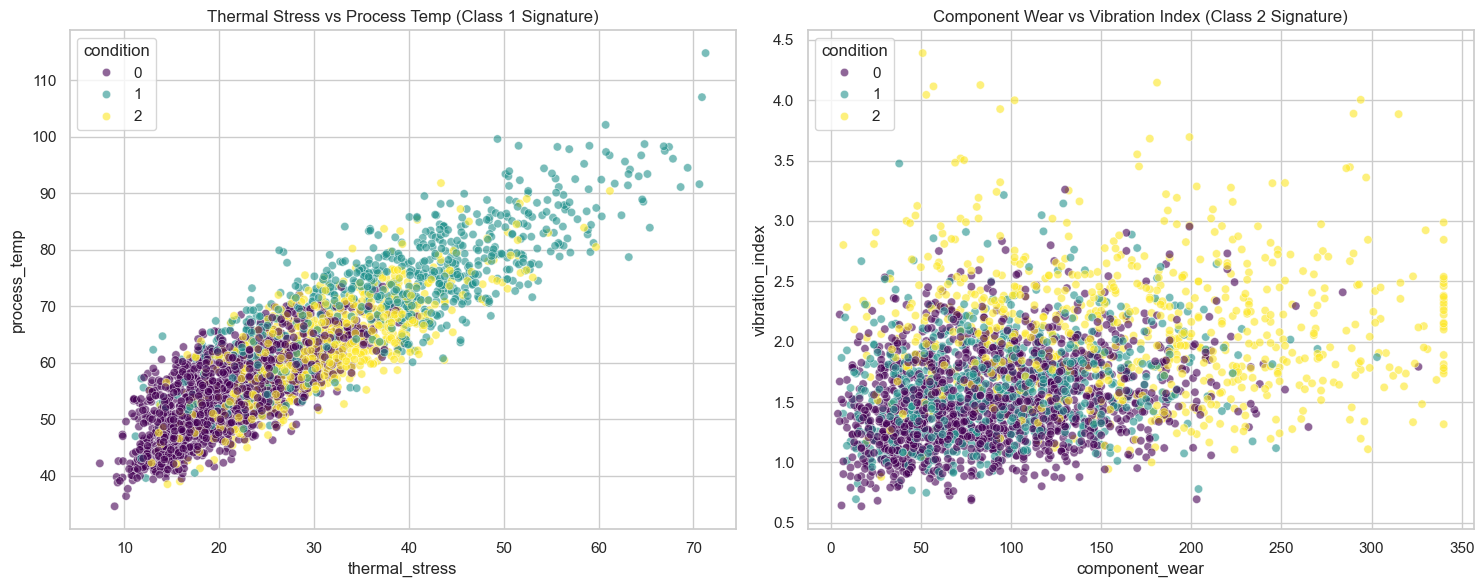

In [7]:
# Scatter plot visualizing how Class 1 and Class 2 separate along different physical degradation axes
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=train_df.sample(n=3000, random_state=42),
    x="thermal_stress",
    y="process_temp",
    hue="condition",
    palette="viridis",
    alpha=0.6,
    ax=ax[0],
)
ax[0].set_title("Thermal Stress vs Process Temp (Class 1 Signature)")

sns.scatterplot(
    data=train_df.sample(n=3000, random_state=42),
    x="component_wear",
    y="vibration_index",
    hue="condition",
    palette="viridis",
    alpha=0.6,
    ax=ax[1],
)
ax[1].set_title("Component Wear vs Vibration Index (Class 2 Signature)")

plt.tight_layout()
plt.show()

In [8]:
def create_features(df):
    data = df.copy()

    # Temperature differential
    data["temp_diff"] = data["process_temp"] - data["ambient_temp"]

    # Mechanical power interaction (Torque * Speed)
    data["calculated_power"] = (
        data["shaft_speed"] * data["drive_torque"]
    ) / 9550.0

    # Physical wear and dynamic strain interaction
    data["wear_vibe_ratio"] = data["component_wear"] * data["vibration_index"]

    # Thermal-to-coolant capacity ratio
    data["thermal_coolant_ratio"] = data["thermal_stress"] / (
        data["coolant_flow"] + 1e-5
    )

    # Unit type mapping
    data["unit_type_enc"] = data["unit_type"].map({"S": 0, "M": 1, "H": 2})

    return data


train_engineered = create_features(train_df)
test_engineered = create_features(test_df)
print("Engineered train shape:", train_engineered.shape)
print("Engineered test shape:", test_engineered.shape)

Engineered train shape: (16000, 18)
Engineered test shape: (4000, 17)
